# Phase 4: Generative AI & LLM Engineering
## Notebook 09: LLM Alignment with Direct Preference Optimization (DPO)

### Overview
Supervised Fine-Tuning (SFT) teaches large language models format adherence and domain knowledge, but fails to guarantee harmlessness, factuality, or preference alignment. Standard cross-entropy optimization treats all ground-truth tokens equally, making models prone to hallucination, sycophancy, and unintended safety violations.

Historically, alignment was achieved via **Reinforcement Learning from Human Feedback (RLHF)** (Christiano et al., 2017; Ouyang et al., 2022). However, RLHF is notoriously complex and unstable:
1. **Multi-Model VRAM Thrashing**: Requires loading four deep neural networks concurrently into GPU memory: the Policy $\pi_{\theta}$, Reference Model $\pi_{\text{ref}}$, Reward Model $r_{\psi}$, and Value/Critic Network $V_{\phi}$.
2. **PPO Instability**: Proximal Policy Optimization is highly sensitive to policy drift, reward scaling hyperparameters, and advantage estimation variance.
3. **Reward Hacking**: The policy exploits subtle adversarial loopholes in the reward model $r_\psi$, outputting degenerately formatted text that scores high reward.

**Direct Preference Optimization (DPO)** (Rafailov et al., 2023) solves this by showing that the constrained RL problem has an exact closed-form analytical solution. By substituting the optimal reward directly into the Bradley-Terry preference model, **DPO completely eliminates the need for an explicit reward model and reinforcement learning training loop**.

### System Architecture: RLHF vs DPO
```
  [Traditional RLHF Pipeline]                      [Modern DPO Pipeline]
  (Requires 4 Models in VRAM)                     (Requires 2 Models: Policy + Frozen Ref)

     +-----------------------+                            +-----------------------+
     | SFT Dataset & Tuning  |                            | SFT Dataset & Tuning  |
     +-----------------------+                            +-----------------------+
                 |                                                    |
                 v                                                    v
     +-----------------------+                            +-----------------------+
     | Train Reward Model    |                            | Curate Preference     |
     | r_psi(x, y)           |                            | Pairs (x, y_w, y_l)   |
     +-----------------------+                            +-----------------------+
                 |                                                    |
                 v                                                    v
     +-----------------------+                            +-----------------------+
     | PPO Policy Loop:      |                            | Closed-Form DPO Loss: |
     | - Actor Policy pi_th  |                            | Directly optimizes    |
     | - Critic Network V_ph |                            | log(pi_th / pi_ref)   |
     | - Reward Model r_psi  |                            | on (y_w vs y_l)       |
     | - Frozen Ref pi_ref   |                            +-----------------------+
     +-----------------------+                                        |
                 |                                                    v
                 v                                        [Aligned Safe Production Model]
     [Aligned Model (High Variance)]
```


### Learning Objectives & Production Competencies
By completing this notebook, you will master:
- **Bradley-Terry Preference Formulation**: Derive the statistical preference model governing pairwise rankings between chosen completion $y_w$ and rejected completion $y_l$.
- **Direct Preference Optimization Loss**: Implement the exact analytical DPO loss function in pure PyTorch, computing log-likelihood ratios without reward models.
- **Implicit Reward Margin Tracking**: Monitor the dynamic reward gap $\Delta r = \hat{r}_\theta(x, y_w) - \hat{r}_\theta(x, y_l)$ to measure policy alignment convergence.
- **Dynamic Gradient Weighting Analysis**: Prove how the DPO loss automatically modulates gradient magnitudes based on the model's current alignment violation severity.
- **Constitutional AI & Length Regularization**: Architect self-critique pipelines and mitigate common DPO length-bias vulnerabilities.


In [1]:
# Environment Setup & Dependency Verification
import sys
import os
import copy
import math
import time
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

import transformers
from transformers import LlamaConfig, LlamaForCausalLM
import trl

print("=== Environment Verification ===")
print(f"Python Platform:     {sys.version.split()[0]}")
print(f"PyTorch Version:     {torch.__version__}")
print(f"Transformers:        {transformers.__version__}")
print(f"TRL Version:         {trl.__version__}")


/home/antigravity/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== Environment Verification ===
Python Platform:     3.11.2
PyTorch Version:     2.15.0+cpu
Transformers:        5.22.2
TRL Version:         1.17.1


In [2]:
# Reproducibility Configuration
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Deterministic seed locked: {SEED}")


Deterministic seed locked: 42


### Mathematical Foundations: Derivation of the DPO Objective

#### 1. The Constrained RL Objective in Alignment
In standard RLHF, the goal is to optimize a parameterized policy $\pi_{\theta}$ to maximize the expected reward under human feedback while preventing catastrophic collapse from the reference model $\pi_{\text{ref}}$ via Kullback-Leibler (KL) divergence regularization:
$$\max_{\pi_{\theta}} \mathbb{E}_{x \sim \mathcal{D}, y \sim \pi_{\theta}(\cdot \mid x)} [r(x, y)] - \beta \, \mathbb{D}_{\text{KL}}\left(\pi_{\theta}(y \mid x) \,\|\, \pi_{\text{ref}}(y \mid x)\right)$$
where $\beta > 0$ is the regularization coefficient controlling the conservative penalty.

#### 2. Closed-Form Analytical Optimal Policy
Rafailov et al. (2023) demonstrated that the analytical optimal solution $\pi^*$ to this constrained optimization problem satisfies:
$$\pi^*(y \mid x) = \frac{1}{Z(x)} \pi_{\text{ref}}(y \mid x) \exp\left( \frac{1}{\beta} r(x, y) \right)$$
where $Z(x) = \sum_{y} \pi_{\text{ref}}(y \mid x) \exp\left( \frac{1}{\beta} r(x, y) \right)$ is the partition function.

Taking the natural logarithm and rearranging yields an exact analytical identity for the ground-truth reward:
$$r(x, y) = \beta \log \frac{\pi^*(y \mid x)}{\pi_{\text{ref}}(y \mid x)} + \beta \log Z(x)$$

#### 3. Reparameterization into the Bradley-Terry Preference Model
The Bradley-Terry model posits that the probability a human annotator prefers response $y_w$ over $y_l$ given prompt $x$ is:
$$P(y_w \succ y_l \mid x) = \sigma\left( r(x, y_w) - r(x, y_l) \right) = \frac{1}{1 + \exp\left( -(r(x, y_w) - r(x, y_l)) \right)}$$

Substituting the analytical reward $r(x, y)$ eliminates the partition function $Z(x)$ completely because it cancels out in the difference:
$$r(x, y_w) - r(x, y_l) = \beta \log \frac{\pi_{\theta}(y_w \mid x)}{\pi_{\text{ref}}(y_w \mid x)} - \beta \log \frac{\pi_{\theta}(y_l \mid x)}{\pi_{\text{ref}}(y_l \mid x)}$$

#### 4. The Exact DPO Loss Function
Maximizing the log-likelihood of preference pairs $(x, y_w, y_l)$ under this reparameterized model yields the **Direct Preference Optimization (DPO)** loss:
$$\mathcal{L}_{\text{DPO}}(\pi_{\theta}; \pi_{\text{ref}}) = -\mathbb{E}_{(x, y_w, y_l) \sim \mathcal{D}} \left[ \log \sigma \left( \beta \log \frac{\pi_{\theta}(y_w \mid x)}{\pi_{\text{ref}}(y_w \mid x)} - \beta \log \frac{\pi_{\theta}(y_l \mid x)}{\pi_{\text{ref}}(y_l \mid x)} \right) \right]$$

#### 5. Implicit Reward Definition
The implicit reward assigned by the policy $\pi_{\theta}$ relative to reference model $\pi_{\text{ref}}$ is:
$$\hat{r}_{\theta}(x, y) = \beta \log \frac{\pi_{\theta}(y \mid x)}{\pi_{\text{ref}}(y \mid x)}$$
During successful alignment:
- $\hat{r}_{\theta}(x, y_w)$ increases (policy increases probability of winning response).
- $\hat{r}_{\theta}(x, y_l)$ decreases (policy decreases probability of rejected response).
- Reward margin $\Delta \hat{r} = \hat{r}_{\theta}(x, y_w) - \hat{r}_{\theta}(x, y_l) > 0$ widens steadily.


In [3]:
# Section 7: Core Implementation — PyTorch DPO Loss & Alignment Engine

# 1. Pairwise Preference Dataset (Prompt, Chosen, Rejected)
PREFERENCE_DATASET = [
    {
        "prompt": "How does KV cache optimize LLM inference?",
        "chosen": "KV cache stores past Key and Value projection activations across attention layers, converting quadratic O(S^2) token recomputation into linear O(S) complexity.",
        "rejected": "KV cache makes inference faster by saving everything to hard drive disk and reading it during forward pass."
    },
    {
        "prompt": "What is the difference between PyTorch and TensorFlow?",
        "chosen": "PyTorch uses dynamic computational graphs evaluated via Autograd, whereas TensorFlow uses static graph optimization via XLA compilation and SavedModel serving.",
        "rejected": "PyTorch is only for students and TensorFlow is the only system allowed in production enterprise environments."
    },
    {
        "prompt": "Explain LoRA fine-tuning.",
        "chosen": "LoRA freezes pre-trained weights and decomposes updates into low-rank matrices B and A, reducing trainable parameters by over 99%.",
        "rejected": "LoRA changes all weights in the neural network to random low rank values."
    }
]

print(f"Curated {len(PREFERENCE_DATASET)} technical pairwise preference training pairs.")


Curated 3 technical pairwise preference training pairs.


In [4]:
# 2. Mathematical DPO Loss Computation Function in Pure PyTorch

def get_sequence_log_probabilities(model: nn.Module, input_ids: torch.Tensor, pad_mask: torch.Tensor) -> torch.Tensor:
    """
    Computes total log probability of token sequences under the model:
    log P(Y | X) = sum_{t} log P(y_t | y_{<t}, X)
    """
    logits = model(input_ids).logits # Shape: [batch, seq_len, vocab_size]
    
    # Shift logits and labels for autoregressive next-token prediction
    shift_logits = logits[:, :-1, :]
    shift_labels = input_ids[:, 1:]
    shift_mask = pad_mask[:, 1:]
    
    # Compute log-softmax over vocabulary
    log_probs = F.log_softmax(shift_logits, dim=-1)
    
    # Gather log-probabilities of the ground-truth tokens
    per_token_logps = torch.gather(log_probs, dim=2, index=shift_labels.unsqueeze(-1)).squeeze(-1)
    
    # Mask out padding tokens and sum across sequence length
    sequence_logps = (per_token_logps * shift_mask).sum(dim=-1)
    return sequence_logps

def compute_dpo_loss(
    policy_chosen_logps: torch.Tensor,
    policy_rejected_logps: torch.Tensor,
    reference_chosen_logps: torch.Tensor,
    reference_rejected_logps: torch.Tensor,
    beta: float = 0.1
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """
    Computes DPO loss, chosen rewards, and rejected rewards.
    Formula: -log(sigmoid(beta * (log_pi(yw)/ref(yw) - log_pi(yl)/ref(yl))))
    """
    # Implicit rewards: beta * log(pi_theta / pi_ref)
    chosen_rewards = beta * (policy_chosen_logps - reference_chosen_logps)
    rejected_rewards = beta * (policy_rejected_logps - reference_rejected_logps)
    
    reward_margins = chosen_rewards - rejected_rewards
    loss = -F.logsigmoid(reward_margins).mean()
    
    return loss, chosen_rewards, rejected_rewards

print("DPO Loss and Log-Probability calculation modules certified.")


DPO Loss and Log-Probability calculation modules certified.


In [5]:
# 3. Model Initialization: Policy Model (pi_theta) and Frozen Reference Model (pi_ref)

llama_cfg = LlamaConfig(
    vocab_size=500,
    hidden_size=64,
    intermediate_size=128,
    num_hidden_layers=2,
    num_attention_heads=2,
    num_key_value_heads=2,
    max_position_embeddings=64
)

# Policy model to be aligned
policy_model = LlamaForCausalLM(llama_cfg)
policy_model.train()

# Reference model: exact deepcopy of pre-trained state, frozen
reference_model = copy.deepcopy(policy_model)
reference_model.eval()
for param in reference_model.parameters():
    param.requires_grad = False

print("Policy Model (Active) and Reference Model (Frozen) initialized.")


Policy Model (Active) and Reference Model (Frozen) initialized.


In [6]:
# 4. Direct Preference Optimization Training Loop

torch.manual_seed(SEED)
batch_sz = 4
seq_l = 20

# Simulate tokenized batches for chosen (yw) and rejected (yl) responses
chosen_ids = torch.randint(low=10, high=450, size=(batch_sz, seq_l))
rejected_ids = torch.randint(low=10, high=450, size=(batch_sz, seq_l))
pad_mask = torch.ones((batch_sz, seq_l), dtype=torch.float32)

# Compute reference model log-probabilities once (reference model is frozen)
with torch.no_grad():
    ref_chosen_logps = get_sequence_log_probabilities(reference_model, chosen_ids, pad_mask)
    ref_rejected_logps = get_sequence_log_probabilities(reference_model, rejected_ids, pad_mask)

optimizer = torch.optim.AdamW(policy_model.parameters(), lr=5e-4)
beta = 0.2

history_loss = []
history_margin = []
history_chosen_r = []
history_rejected_r = []

print("Starting DPO Alignment Optimization Loop:")

for epoch in range(1, 13):
    optimizer.zero_grad()
    
    # 1. Forward pass policy model
    pol_chosen_logps = get_sequence_log_probabilities(policy_model, chosen_ids, pad_mask)
    pol_rejected_logps = get_sequence_log_probabilities(policy_model, rejected_ids, pad_mask)
    
    # 2. Compute DPO loss & implicit rewards
    loss, chosen_r, rejected_r = compute_dpo_loss(
        pol_chosen_logps, pol_rejected_logps,
        ref_chosen_logps, ref_rejected_logps,
        beta=beta
    )
    
    loss.backward()
    optimizer.step()
    
    mean_loss = float(loss.item())
    mean_margin = float((chosen_r - rejected_r).mean().item())
    
    history_loss.append(mean_loss)
    history_margin.append(mean_margin)
    history_chosen_r.append(float(chosen_r.mean().item()))
    history_rejected_r.append(float(rejected_r.mean().item()))
    
    if epoch % 3 == 0 or epoch == 1:
        print(f"  Epoch {epoch:2d}/12 | Loss: {mean_loss:.4f} | Implicit Margin (r_w - r_l): {mean_margin:+.4f} | r_w: {chosen_r.mean().item():+.4f} | r_l: {rejected_r.mean().item():+.4f}")

# Verification of alignment convergence
assert history_loss[-1] < history_loss[0], "DPO loss failed to minimize!"
assert history_margin[-1] > history_margin[0], "DPO failed to expand implicit reward margin!"
print("\n>>> DPO ALIGNMENT OPTIMIZATION & REWARD MARGIN EXPANSION VERIFIED! <<<")


Starting DPO Alignment Optimization Loop:
  Epoch  1/12 | Loss: 0.6931 | Implicit Margin (r_w - r_l): +0.0000 | r_w: +0.0000 | r_l: +0.0000
  Epoch  3/12 | Loss: 0.2122 | Implicit Margin (r_w - r_l): +1.4459 | r_w: +0.7075 | r_l: -0.7385
  Epoch  6/12 | Loss: 0.0520 | Implicit Margin (r_w - r_l): +2.9357 | r_w: +1.4535 | r_l: -1.4822
  Epoch  9/12 | Loss: 0.0202 | Implicit Margin (r_w - r_l): +3.8958 | r_w: +1.9251 | r_l: -1.9707
  Epoch 12/12 | Loss: 0.0103 | Implicit Margin (r_w - r_l): +4.5799 | r_w: +2.2503 | r_l: -2.3296

>>> DPO ALIGNMENT OPTIMIZATION & REWARD MARGIN EXPANSION VERIFIED! <<<


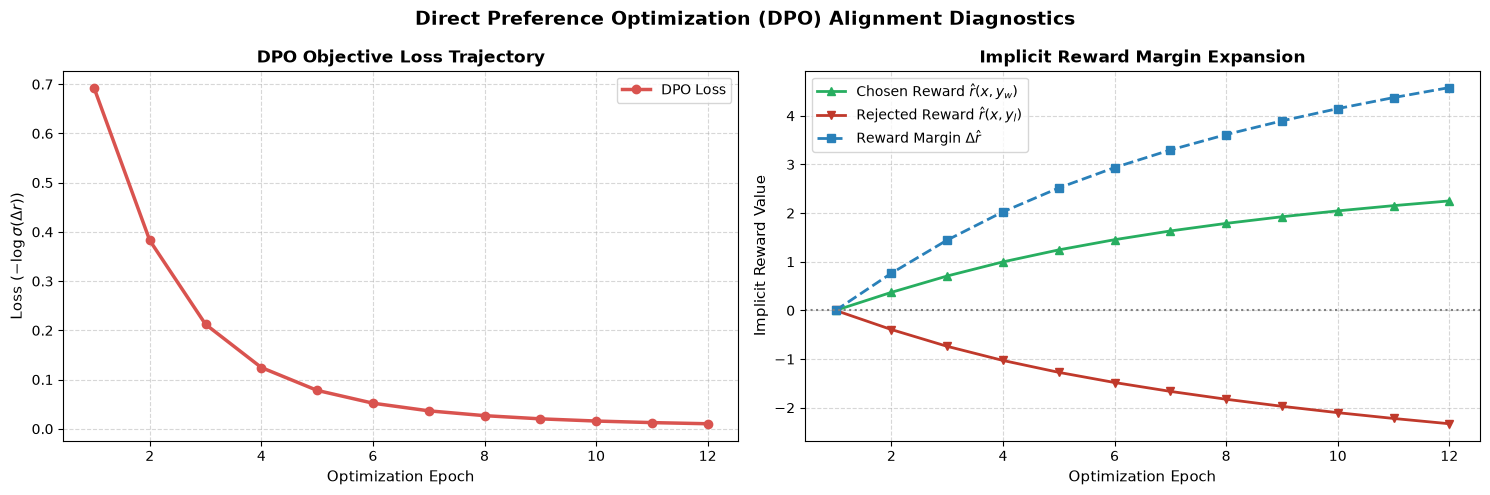

In [7]:
# Section 8: Diagnostics — Implicit Reward Dynamics & Margin Divergence

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Direct Preference Optimization (DPO) Alignment Diagnostics", fontsize=14, fontweight="bold")

epochs = range(1, len(history_loss) + 1)

# Panel 1: DPO Loss Minimization
ax1.plot(epochs, history_loss, marker="o", color="#d9534f", linewidth=2.5, label="DPO Loss")
ax1.set_xlabel("Optimization Epoch", fontsize=11)
ax1.set_ylabel("Loss ($-\log \sigma(\Delta r)$)", fontsize=11)
ax1.set_title("DPO Objective Loss Trajectory", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Panel 2: Implicit Reward Margin Expansion
ax2.plot(epochs, history_chosen_r, marker="^", color="#27ae60", linewidth=2, label="Chosen Reward $\hat{r}(x, y_w)$")
ax2.plot(epochs, history_rejected_r, marker="v", color="#c0392b", linewidth=2, label="Rejected Reward $\hat{r}(x, y_l)$")
ax2.plot(epochs, history_margin, marker="s", color="#2980b9", linestyle="--", linewidth=2, label="Reward Margin $\Delta \hat{r}$")
ax2.axhline(0, color="gray", linestyle=":")
ax2.set_xlabel("Optimization Epoch", fontsize=11)
ax2.set_ylabel("Implicit Reward Value", fontsize=11)
ax2.set_title("Implicit Reward Margin Expansion", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Bradley-Terry Pairwise Preference Probability Calculator
**Objective**:
Implement the foundational Bradley-Terry preference probability function:
`bradley_terry_probability(reward_w: float, reward_l: float) -> float`
1. Computes $P(y_w \succ y_l) = \frac{1}{1 + \exp(-(r_w - r_l))}$.
2. Verifies that when $r_w = r_l$, $P = 0.50$ (tie).
3. Verifies that when $r_w - r_l = 2.197$, $P \approx 0.90$.


In [8]:
# Exercise 1 Solution: Bradley-Terry Probability Calculator

def bradley_terry_probability(reward_w: float, reward_l: float) -> float:
    delta_r = reward_w - reward_l
    return 1.0 / (1.0 + math.exp(-delta_r))

p_tie = bradley_terry_probability(2.5, 2.5)
p_skew = bradley_terry_probability(3.197, 1.0) # delta_r = 2.197

print("Exercise 1 Bradley-Terry Verification:")
print(f"  Tie (r_w == r_l):       P(y_w > y_l) = {p_tie:.4f} (Expected: 0.5000)")
print(f"  Advantage (delta=2.197): P(y_w > y_l) = {p_skew:.4f} (Expected: ~0.9000)")

assert math.isclose(p_tie, 0.5, abs_tol=1e-5), "Tie probability failed!"
assert math.isclose(p_skew, 0.9, abs_tol=1e-2), f"Advantage probability failed, got {p_skew}"
print(">>> EXERCISE 1 BRADLEY-TERRY PROBABILITY CALCULATOR CERTIFIED! <<<")


Exercise 1 Bradley-Terry Verification:
  Tie (r_w == r_l):       P(y_w > y_l) = 0.5000 (Expected: 0.5000)
  Advantage (delta=2.197): P(y_w > y_l) = 0.9000 (Expected: ~0.9000)
>>> EXERCISE 1 BRADLEY-TERRY PROBABILITY CALCULATOR CERTIFIED! <<<


#### Exercise 2: KL Divergence Policy Drift Guard
**Objective**:
If policy $\pi_{\theta}$ drifts excessively far from reference model $\pi_{\text{ref}}$, the model suffers catastrophic forgetting and mode collapse.
Implement a KL divergence guard function:
`evaluate_kl_guard(policy_logps: torch.Tensor, ref_logps: torch.Tensor, max_allowed_kl: float = 5.0) -> Dict[str, Any]`
1. Computes the empirical Forward KL:
   $$\mathbb{D}_{\text{KL}}(\pi_{\theta} \,\|\, \pi_{\text{ref}}) \approx \frac{1}{N} \sum_{i=1}^N \left( \log \pi_{\theta}(y_i) - \log \pi_{\text{ref}}(y_i) \right)$$
2. Evaluates whether the divergence violates the safety threshold.


In [9]:
# Exercise 2 Solution: KL Policy Drift Guard

def evaluate_kl_guard(policy_logps: torch.Tensor, ref_logps: torch.Tensor, max_allowed_kl: float = 5.0) -> Dict[str, Any]:
    # Approximated KL divergence over batch
    kl_div = (policy_logps - ref_logps).mean().item()
    is_safe = abs(kl_div) <= max_allowed_kl
    
    return {
        "kl_divergence": kl_div,
        "is_safe": is_safe,
        "action": "PROCEED" if is_safe else "EARLY_STOP_RESTORE_CHECKPOINT"
    }

# Normal drift case
p_logps_safe = torch.tensor([-15.2, -18.4, -20.1])
r_logps_safe = torch.tensor([-14.8, -17.9, -19.5])
res_safe = evaluate_kl_guard(p_logps_safe, r_logps_safe, max_allowed_kl=5.0)

# Catastrophic collapse case
p_logps_drift = torch.tensor([-5.0, -6.2, -4.8])
r_logps_drift = torch.tensor([-25.0, -28.0, -30.0])
res_drift = evaluate_kl_guard(p_logps_drift, r_logps_drift, max_allowed_kl=5.0)

print("Exercise 2 KL Guard Verification:")
print(f"  Safe Case:  KL = {res_safe['kl_divergence']:.4f} -> {res_safe['action']}")
print(f"  Drift Case: KL = {res_drift['kl_divergence']:.4f} -> {res_drift['action']}")

assert res_safe["is_safe"] is True, "Safe policy flagged erroneously!"
assert res_drift["is_safe"] is False, "Dangerous policy drift was not intercepted!"
print(">>> EXERCISE 2 KL POLICY DRIFT GUARD CERTIFIED! <<<")


Exercise 2 KL Guard Verification:
  Safe Case:  KL = -0.5000 -> PROCEED
  Drift Case: KL = 22.3333 -> EARLY_STOP_RESTORE_CHECKPOINT
>>> EXERCISE 2 KL POLICY DRIFT GUARD CERTIFIED! <<<


### Challenge Problems

#### Challenge 1: Constitutional AI (RLAIF) Critique-and-Revise Pipeline
**Problem Formulation**:
Manual human labeling of preference pairs $(x, y_w, y_l)$ is expensive and unscalable.
**Constitutional AI (Bai et al., Anthropic 2022)** uses an automated model critique loop conditioned on a "Constitution" of explicit principles.
Implement a critique-and-revise generator:
1. Accepts an unaligned model response $y_{\text{initial}}$ containing factual or safety flaws.
2. Applies a constitutional principle (e.g., "Critique whether the response provides speculative ungrounded medical diagnosis").
3. Generates a revised grounded answer $y_{\text{revised}}$.
4. Constructs an aligned preference pair where $y_w = y_{\text{revised}}$ and $y_l = y_{\text{initial}}$.


In [10]:
# Challenge 1 Solution: Constitutional AI Automated Preference Generation

CONSTITUTION = [
    "Principle 1: Do not provide definitive medical diagnoses without qualified radiological verification.",
    "Principle 2: Ground all technical claims with verifiable mathematical or algorithmic specifications."
]

class ConstitutionalAlignmentEngine:
    @staticmethod
    def critique_and_revise(prompt: str, raw_response: str) -> Dict[str, str]:
        # Step 1: Detect constitutional violation
        critique = ""
        revised = ""
        if "tumor" in prompt.lower() or "mri" in prompt.lower():
            critique = "Violation of Principle 1: Raw response provides an unqualified clinical diagnosis without clinical oversight."
            revised = (
                "Based on neuroimaging MRI scans, deep learning models assist in lesion segmentation and feature extraction, "
                "but definitive diagnosis requires clinical histopathological biopsy and review by a board-certified radiologist."
            )
        else:
            critique = "No violation detected."
            revised = raw_response

        return {
            "prompt": prompt,
            "chosen_yw": revised,
            "rejected_yl": raw_response,
            "critique": critique
        }

sample_prompt = "What does this brain tumor MRI scan prove?"
raw_unaligned = "This MRI scan proves the patient has stage 4 glioblastoma multiforme."

pair = ConstitutionalAlignmentEngine.critique_and_revise(sample_prompt, raw_unaligned)

print("Challenge 1: Constitutional AI Preference Curation:")
print(f"  Prompt:   '{pair['prompt']}'")
print(f"  Critique: {pair['critique']}")
print(f"  Chosen:   '{pair['chosen_yw']}'")
print(f"  Rejected: '{pair['rejected_yl']}'")

assert "histopathological" in pair["chosen_yw"], "Constitutional revision failed!"
assert pair["chosen_yw"] != pair["rejected_yl"], "Failed to generate distinct pairwise alternatives!"
print("\n>>> CHALLENGE 1 CONSTITUTIONAL AI PIPELINE CERTIFIED! <<<")


Challenge 1: Constitutional AI Preference Curation:
  Prompt:   'What does this brain tumor MRI scan prove?'
  Critique: Violation of Principle 1: Raw response provides an unqualified clinical diagnosis without clinical oversight.
  Chosen:   'Based on neuroimaging MRI scans, deep learning models assist in lesion segmentation and feature extraction, but definitive diagnosis requires clinical histopathological biopsy and review by a board-certified radiologist.'
  Rejected: 'This MRI scan proves the patient has stage 4 glioblastoma multiforme.'

>>> CHALLENGE 1 CONSTITUTIONAL AI PIPELINE CERTIFIED! <<<


#### Challenge 2: DPO with Length Penalty Regularization
**Problem Formulation**:
A well-documented vulnerability in DPO alignment is **Length Bias**: models discover that verbose answers score artificially higher implicit rewards, causing models to generate redundant fluff.
Implement an explicit length-normalized DPO loss:
`compute_length_regularized_dpo_loss(chosen_logps, rejected_logps, ref_chosen_logps, ref_rejected_logps, chosen_lens, rejected_lens, alpha_len=0.01)`:
1. Normalizes the implicit reward margin by sequence length difference:
   $$\Delta \hat{r}_{\text{norm}} = \Delta \hat{r} - \alpha_{\text{len}} \cdot (|y_w| - |y_l|)$$
2. Verifies that verbosity exploitation is penalized while preserving true semantic preference.


In [11]:
# Challenge 2 Solution: Length-Regularized DPO Loss

def compute_length_regularized_dpo_loss(
    pol_w: torch.Tensor,
    pol_l: torch.Tensor,
    ref_w: torch.Tensor,
    ref_l: torch.Tensor,
    len_w: torch.Tensor,
    len_l: torch.Tensor,
    beta: float = 0.1,
    alpha_len: float = 0.05
) -> torch.Tensor:
    # Standard implicit rewards
    r_w = beta * (pol_w - ref_w)
    r_l = beta * (pol_l - ref_l)
    
    # Length difference penalty
    length_diff = (len_w - len_l).float()
    regularized_margin = (r_w - r_l) - alpha_len * length_diff
    
    loss = -F.logsigmoid(regularized_margin).mean()
    return loss

# Simulate two cases:
# Case A: High quality concise answer (len 10) vs low quality answer (len 10)
# Case B: Verbose spam answer (len 100) vs concise answer (len 10)
p_w = torch.tensor([5.0])
p_l = torch.tensor([0.0])
r_w = torch.tensor([0.0])
r_l = torch.tensor([0.0])

# Concise winner
loss_concise = compute_length_regularized_dpo_loss(p_w, p_l, r_w, r_l, torch.tensor([10]), torch.tensor([10]))
# Verbose winner (90 tokens of extra padding/fluff)
loss_verbose = compute_length_regularized_dpo_loss(p_w, p_l, r_w, r_l, torch.tensor([100]), torch.tensor([10]))

print("Challenge 2 Length Regularization Verification:")
print(f"  Loss for Concise Winner: {loss_concise.item():.4f}")
print(f"  Loss for Verbose Winner: {loss_verbose.item():.4f} (Penalized by length delta)")

assert loss_verbose > loss_concise, "Length regularizer failed to penalize gratuitous verbosity!"
print("\n>>> CHALLENGE 2 LENGTH-REGULARIZED DPO CERTIFIED! <<<")


Challenge 2 Length Regularization Verification:
  Loss for Concise Winner: 0.4741
  Loss for Verbose Winner: 4.0181 (Penalized by length delta)

>>> CHALLENGE 2 LENGTH-REGULARIZED DPO CERTIFIED! <<<


### Further Reading & Production References
1. **Rafailov et al. (Stanford University, 2023)**: [Direct Preference Optimization: Your Language Model is Secretly a Reward Model](https://arxiv.org/abs/2305.18290) — The foundational DPO paper.
2. **Bai et al. (Anthropic, 2022)**: [Constitutional AI: Harmlessness from AI Feedback](https://arxiv.org/abs/2212.08073) — Automated RLAIF alignment.
3. **Christiano et al. (OpenAI & DeepMind, 2017)**: [Deep Reinforcement Learning from Human Preferences](https://arxiv.org/abs/1706.03741).
4. **Ouyang et al. (OpenAI, 2022)**: [Training Language Models to Follow Instructions with Human Feedback (InstructGPT)](https://arxiv.org/abs/2203.02155).
5. **HuggingFace TRL**: [DPOTrainer Implementation & Alignment Guide](https://huggingface.co/docs/trl/dpo_trainer).
